# 02 - Preparación de los datos y entrenamiento de modelos

**Proyecto de aula - Modelos y Simulación de Sistemas II**

**Integrantes:** Kelly Julieth Arango Henao, Lisbeth Cataño Sepulveda

## Introducción

En este notebook se prepara el conjunto de datos y se entrenan y comparan los cinco modelos del proyecto:

| Tipo de modelo | Modelo |
|---|---|
| Paramétrico | Regresión logística |
| No paramétrico | KNN |
| Ensamble de árboles | Random Forest |
| Red neuronal | Perceptrón multicapa (MLP) |
| Máquina de vectores de soporte | SVM |

Los pasos son:

1. Cargar los datos y eliminar los duplicados (igual que en el notebook 01).
2. Separar las variables de entrada de la variable objetivo.
3. Dividir los datos en entrenamiento y prueba.
4. Definir el preprocesamiento (estandarizar solo `Time` y `Amount`).
5. Entrenar cada modelo con validación cruzada y revisar el efecto de sus hiperparámetros.
6. Comparar los cinco modelos en una sola tabla.

El conjunto de prueba se mantiene completamente aparte durante la selección
de modelos e hiperparámetros, y solo se usa al final del notebook, una sola
vez, para evaluar los cinco modelos ya entrenados con sus mejores
hiperparámetros.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Antes de ejecutar este notebook

Igual que en el notebook 01, este código busca el archivo `creditcard.csv` en las ubicaciones habituales (carpeta `data/` del proyecto o Google Drive en Colab). Si no lo encuentra, pide cargarlo manualmente.

In [3]:
import os

RUTA_DATOS = None

candidatos = [
    "../data/creditcard.csv",
    "data/creditcard.csv",
    "/content/drive/MyDrive/creditcard.csv",
    "/content/drive/MyDrive/data/creditcard.csv",
    "/content/drive/MyDrive/Colab Notebooks/data/creditcard.csv",
    "creditcard.csv"
]

for ruta in candidatos:
    if os.path.exists(ruta):
        RUTA_DATOS = ruta
        break

if RUTA_DATOS is None:
    try:
        import google.colab
        en_colab = True
    except ImportError:
        en_colab = False

    if en_colab:
        from google.colab import drive

        print("No se encontró el archivo. Conectando Google Drive...")
        drive.mount('/content/drive')

        for ruta in candidatos:
            if os.path.exists(ruta):
                RUTA_DATOS = ruta
                break

        if RUTA_DATOS is None:
            from google.colab import files
            print("Selecciona el archivo creditcard.csv")
            subido = files.upload()

            if subido:
                RUTA_DATOS = list(subido.keys())[0]

if RUTA_DATOS is None:
    raise FileNotFoundError(
        "No se encontró creditcard.csv. Revisa la carpeta data/ "
        "o consulta el README para descargar el archivo."
    )

print("Archivo de datos utilizado:", RUTA_DATOS)

Archivo de datos utilizado: /content/drive/MyDrive/Colab Notebooks/data/creditcard.csv


In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.metaestimators import available_if

sns.set_style("whitegrid")

# Semilla fija para que los resultados se puedan repetir
SEMILLA = 42

# Carpeta para guardar tablas y gráficas
CARPETA_RESULTADOS = (
    "../resultados"
    if os.path.isdir("..") and os.path.isdir("../notebooks")
    else "resultados"
)
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

print("Carpeta de resultados:", CARPETA_RESULTADOS)

Carpeta de resultados: resultados


## 1. Cargar y limpiar los datos

Se cargan los datos y se eliminan los registros duplicados **antes** de dividir en entrenamiento y prueba. Si se dividiera primero, una transacción repetida podría quedar una vez en entrenamiento y otra en prueba, y el modelo parecería mejor de lo que realmente es.

In [5]:
df = pd.read_csv(RUTA_DATOS)
filas_originales = len(df)

df = df.drop_duplicates().reset_index(drop=True)

print("Filas originales:", filas_originales)
print("Filas después de eliminar duplicados:", len(df))
print("Duplicados eliminados:", filas_originales - len(df))
print("Fraudes:", int(df["Class"].sum()), f"({df['Class'].mean() * 100:.3f} %)")

Filas originales: 284807
Filas después de eliminar duplicados: 283726
Duplicados eliminados: 1081
Fraudes: 473 (0.167 %)


## 2. Variables de entrada (X) y variable objetivo (y)

`Class` es lo que se quiere predecir, así que no puede estar entre las variables de entrada. Si estuviera, el modelo tendría la respuesta y no aprendería nada.

In [6]:
X = df.drop(columns="Class")
y = df["Class"]

print("Variables de entrada:", X.shape[1])
print("Columnas:", X.columns.tolist())

Variables de entrada: 30
Columnas: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## 3. División en entrenamiento y prueba

Se separa el 80 % de los datos para entrenamiento y el 20 % para prueba. La división es **estratificada**: entrenamiento y prueba conservan la misma proporción de fraudes que el conjunto completo. Sin esto, con tan pocos fraudes, el conjunto de prueba podría quedar con muy pocos o con demasiados.

La semilla fija (`random_state=42`) permite repetir exactamente la misma división.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEMILLA
)

resumen_particion = pd.DataFrame({
    "Transacciones": [len(y_train), len(y_test)],
    "Fraudes": [int(y_train.sum()), int(y_test.sum())],
    "% de fraude": [y_train.mean() * 100, y_test.mean() * 100]
}, index=["Entrenamiento", "Prueba"]).round(3)

resumen_particion

,Transacciones,Fraudes,% de fraude
Entrenamiento,226980,378,0.167
Prueba,56746,95,0.167


Con pocos fraudes en el conjunto de prueba, las métricas que se calculen sobre él tendrán intervalos de confianza amplios. Por eso en el reporte se presentan junto con su intervalo.

## 4. Preprocesamiento

- `Time` y `Amount` se estandarizan, porque están en escalas muy distintas a las demás.
- `V1` a `V28` **no se estandarizan de nuevo**: ya son componentes de un PCA y vienen en una escala comparable.

El estandarizador se mete dentro de un `Pipeline`. Así, en cada partición de la validación cruzada se calcula la media y la desviación **solo con los datos de entrenamiento de esa partición**, y no se filtra información de los datos de validación.

In [8]:
columnas_a_escalar = ["Time", "Amount"]

preprocesamiento = ColumnTransformer(
    transformers=[("escalar", StandardScaler(), columnas_a_escalar)],
    remainder="passthrough"   # V1-V28 pasan sin cambios
)

## 5. Manejo del desbalance

Con solo 0,17 % de fraudes, generar muchos ejemplos sintéticos con SMOTE puede deformar la zona donde se separan las clases. Por eso se empieza con la opción más sencilla: **ponderar las clases** (`class_weight="balanced"`). Así, equivocarse en un fraude pesa más que equivocarse en una transacción legítima. Más adelante se pueden comparar otras alternativas (submuestreo, ADASYN).

**Referencia para la métrica principal.** El AUPRC (área bajo la curva Precision-Recall) de un modelo que no sabe nada es igual a la proporción de fraudes. Cualquier modelo útil tiene que superar ese valor.

In [9]:
referencia_auprc = y_train.mean()
print(f"AUPRC de un modelo sin información (proporción de fraudes): {referencia_auprc:.4f}")

AUPRC de un modelo sin información (proporción de fraudes): 0.0017


## 6. Validación cruzada

Se usa validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento. En cada vuelta, 4 partes se usan para entrenar y 1 para validar, y cada parte conserva la proporción de fraudes.

Se calculan varias métricas. El AUPRC es la principal; el resto sirve para entender mejor el comportamiento del modelo:

- **AUPRC** (`average_precision`): resume el balance entre precision y recall sin depender de un umbral.
- **ROC-AUC:** capacidad general de separar las dos clases.
- **Precision:** de las transacciones que el modelo marca como fraude, cuántas lo son.
- **Recall:** de los fraudes reales, cuántos detecta el modelo.
- **F1:** combina precision y recall.
- **MCC:** coeficiente de correlación de Matthews, definido en el reporte.

In [10]:
K = 5
validacion = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEMILLA)

metricas = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "mcc": "matthews_corrcoef",
}

## 7. Regresión logística

Es el modelo paramétrico del proyecto. Su hiperparámetro principal es `C`, que controla qué tanto se penalizan los coeficientes grandes: un `C` pequeño regulariza fuerte (modelo más simple) y un `C` grande regulariza poco.

Se prueba una malla de valores de `C` y se elige el que da mejor AUPRC en validación.

In [11]:
modelo_lr = Pipeline([
    ("prep", preprocesamiento),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=SEMILLA
    ))
])

malla_lr = {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]}

busqueda_lr = GridSearchCV(
    estimator=modelo_lr,
    param_grid=malla_lr,
    scoring=metricas,
    refit="average_precision",
    cv=validacion,
    return_train_score=True,
    n_jobs=-1
)

busqueda_lr.fit(X_train, y_train)

print("Mejor valor de C:", busqueda_lr.best_params_["clf__C"])
print(f"Mejor AUPRC en validación: {busqueda_lr.best_score_:.4f}")

Mejor valor de C: 0.1
Mejor AUPRC en validación: 0.7545


## 8. Efecto del hiperparámetro `C`

La tabla y la gráfica muestran cómo cambia el desempeño al variar `C`, tanto en entrenamiento como en validación. Si el desempeño en entrenamiento es mucho mayor que en validación, el modelo se está sobreajustando.

In [12]:
res = busqueda_lr.cv_results_

tabla_C = pd.DataFrame({
    "C": [float(c) for c in res["param_clf__C"]],
    "AUPRC entrenamiento": res["mean_train_average_precision"],
    "AUPRC validación": res["mean_test_average_precision"],
    "Desv. AUPRC validación": res["std_test_average_precision"],
    "ROC-AUC validación": res["mean_test_roc_auc"],
    "Recall validación": res["mean_test_recall"],
    "Precision validación": res["mean_test_precision"],
}).round(4)

tabla_C.to_csv(f"{CARPETA_RESULTADOS}/regresion_logistica_efecto_C.csv", index=False)
tabla_C

,C,AUPRC entrenamiento,AUPRC validación,Desv. AUPRC validación,ROC-AUC validación,Recall validación,Precision validación
0,0.001,0.7367,0.7356,0.0255,0.9826,0.9074,0.0677
1,0.010,0.7565,0.7541,0.0250,0.9815,0.9074,0.0615
2,0.100,0.7568,0.7545,0.0256,0.9814,0.9153,0.0605
3,1.000,0.7563,0.7541,0.0267,0.9814,0.9179,0.0606
4,10.000,0.7563,0.7541,0.0266,0.9814,0.9179,0.0606
5,100.000,0.7563,0.7541,0.0266,0.9814,0.9179,0.0606


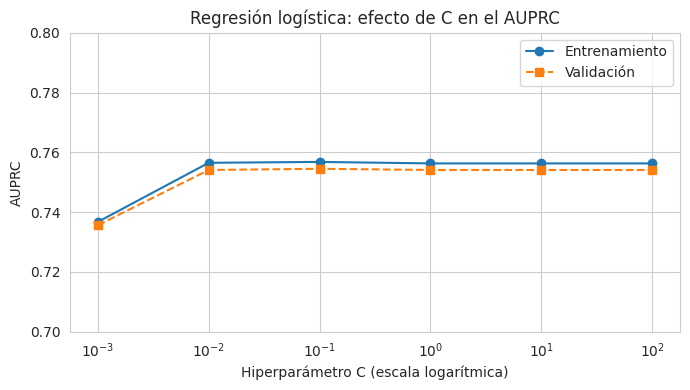

In [13]:
plt.figure(figsize=(7, 4))

plt.semilogx(tabla_C["C"], tabla_C["AUPRC entrenamiento"], marker="o", label="Entrenamiento")
plt.semilogx(tabla_C["C"], tabla_C["AUPRC validación"], marker="s", linestyle="--", label="Validación")
plt.ylim(0.70, 0.80)

plt.xlabel("Hiperparámetro C (escala logarítmica)")
plt.ylabel("AUPRC")
plt.title("Regresión logística: efecto de C en el AUPRC")
plt.legend()
plt.tight_layout()

plt.savefig(f"{CARPETA_RESULTADOS}/regresion_logistica_efecto_C.png", dpi=200)
plt.show()

## 9. Resultados del mejor modelo con intervalos de confianza

Para cada métrica se calcula el promedio de las 5 particiones y un intervalo de confianza del 95 % (distribución t de Student, con 4 grados de libertad). Como las particiones comparten datos de entrenamiento, el intervalo es aproximado, pero sirve para ver qué tan estable es el resultado.

In [14]:
def resumen_con_ic(cv_res, indice, nombre_metrica, conjunto, k=K):
    """Promedio e IC 95 % de una métrica a partir de los valores de cada partición."""
    valores = np.array([cv_res[f"split{i}_{conjunto}_{nombre_metrica}"][indice] for i in range(k)])
    media = valores.mean()
    desv = valores.std(ddof=1)
    mitad = stats.t.ppf(0.975, k - 1) * desv / np.sqrt(k)
    return media, mitad

indice_mejor = busqueda_lr.best_index_

nombres_legibles = {
    "average_precision": "AUPRC",
    "roc_auc": "ROC-AUC",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1-score",
    "mcc": "MCC",
}

filas = []
for nombre in metricas:
    m_tr, h_tr = resumen_con_ic(res, indice_mejor, nombre, "train")
    m_va, h_va = resumen_con_ic(res, indice_mejor, nombre, "test")   # "test" aquí es la partición de validación
    filas.append({
        "Métrica": nombres_legibles[nombre],
        "Entrenamiento": f"{m_tr:.4f} ± {h_tr:.4f}",
        "Validación": f"{m_va:.4f} ± {h_va:.4f}",
    })

tabla_mejor = pd.DataFrame(filas)
tabla_mejor.to_csv(f"{CARPETA_RESULTADOS}/regresion_logistica_mejor_modelo.csv", index=False)

print("Regresión logística con C =", busqueda_lr.best_params_["clf__C"])
tabla_mejor

Regresión logística con C = 0.1


,Métrica,Entrenamiento,Validación
0,AUPRC,0.7568 ± 0.0108,0.7545 ± 0.0355
1,ROC-AUC,0.9904 ± 0.0020,0.9814 ± 0.0112
2,Precision,0.0614 ± 0.0081,0.0605 ± 0.0093
3,Recall,0.9259 ± 0.0104,0.9153 ± 0.0380
4,F1-score,0.1152 ± 0.0142,0.1133 ± 0.0162
5,MCC,0.2350 ± 0.0165,0.2315 ± 0.0182


### Interpretación

Con `class_weight="balanced"` y el umbral de decisión por defecto (0,5), el modelo marca como fraude muchas transacciones que no lo son. Por eso se ve un **recall alto y una precision baja**. El AUPRC no depende del umbral, así que es la métrica más justa para comparar modelos.

- Mejor valor de `C`: 0,1. Entre 0,01 y 100 el AUPRC casi no cambia, así que la regularización tiene poco efecto en este problema.
- AUPRC en validación: 0,7545, frente a 0,0017 de un modelo sin información.
- Entrenamiento y validación: 0,7568 y 0,7545. Son casi iguales, por lo que no hay sobreajuste.
- Precision y recall: recall de 0,9153 y precision de 0,0605. El modelo detecta cerca del 91 % de los fraudes, pero por cada fraude real marca unas 15 transacciones legítimas como fraude.

## 10. Herramientas para comparar los modelos

Antes de entrenar los demás modelos se definen tres herramientas que se reutilizan.

**Submuestreo de la clase mayoritaria.** KNN y la red neuronal no tienen ponderación de clases, y la SVM con 227 mil filas es muy lenta. Para estos tres modelos se usa submuestreo: en cada entrenamiento se conservan todos los fraudes y solo una muestra aleatoria de transacciones legítimas (20 por cada fraude). Esto se hace **únicamente con los datos de entrenamiento de cada partición**; los datos de validación se dejan completos y con su proporción real de fraudes, así que las métricas siguen siendo comparables entre modelos.

La regresión logística y el Random Forest usan todos los datos con ponderación de clases.

In [17]:
RELACION_SUBMUESTREO = 20   # transacciones legítimas conservadas por cada fraude


class ConSubmuestreo(ClassifierMixin, BaseEstimator):
    """Envuelve un clasificador y submuestrea la clase mayoritaria SOLO al entrenar.

    Al predecir no modifica los datos, por eso se puede usar dentro de la
    validación cruzada sin que los datos de validación se alteren.
    """

    def __init__(self, estimador=None, relacion=RELACION_SUBMUESTREO, semilla=SEMILLA):
        self.estimador = estimador
        self.relacion = relacion
        self.semilla = semilla

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        rng = np.random.default_rng(self.semilla)

        idx_fraude = np.where(y == 1)[0]
        idx_legit = np.where(y == 0)[0]
        n_legit = min(len(idx_legit), self.relacion * len(idx_fraude))
        idx_legit = rng.choice(idx_legit, size=n_legit, replace=False)

        idx = np.concatenate([idx_fraude, idx_legit])
        rng.shuffle(idx)

        self.estimador_ = clone(self.estimador).fit(X[idx], y[idx])
        self.classes_ = self.estimador_.classes_
        return self

    def predict(self, X):
        return self.estimador_.predict(X)

    @available_if(lambda self: hasattr(self.estimador, "predict_proba"))
    def predict_proba(self, X):
        return self.estimador_.predict_proba(X)

    @available_if(lambda self: hasattr(self.estimador, "decision_function"))
    def decision_function(self, X):
        return self.estimador_.decision_function(X)

In [18]:
resultados_modelos = {"Regresión logística": busqueda_lr}
mallas_usadas = {"Regresión logística": malla_lr}


def entrenar_modelo(nombre, modelo, malla):
    """Entrena un modelo con la búsqueda de hiperparámetros y la validación cruzada
    definidas arriba, y devuelve la búsqueda y la tabla con todas las combinaciones."""
    busqueda = GridSearchCV(
        estimator=modelo,
        param_grid=malla,
        scoring=metricas,
        refit="average_precision",
        cv=validacion,
        return_train_score=True,
        n_jobs=-1
    )

    inicio = time.time()
    busqueda.fit(X_train, y_train)
    duracion = time.time() - inicio

    r = busqueda.cv_results_

    # Una columna por hiperparámetro (se quita el prefijo del pipeline)
    parametros = pd.DataFrame(r["params"])
    parametros.columns = [c.split("__")[-1] for c in parametros.columns]
    parametros = parametros.astype(str)

    tabla = parametros.copy()
    tabla["AUPRC entrenamiento"] = r["mean_train_average_precision"]
    tabla["AUPRC validación"] = r["mean_test_average_precision"]
    tabla["Desv. AUPRC validación"] = r["std_test_average_precision"]
    tabla["Recall validación"] = r["mean_test_recall"]
    tabla["Precision validación"] = r["mean_test_precision"]
    tabla = tabla.round(4)

    archivo = nombre.lower().replace(" ", "_").replace("ó", "o").replace("í", "i")
    tabla.to_csv(f"{CARPETA_RESULTADOS}/{archivo}_efecto_hiperparametros.csv", index=False)

    resultados_modelos[nombre] = busqueda
    mallas_usadas[nombre] = malla

    print(f"{nombre}: búsqueda terminada en {duracion / 60:.1f} minutos")
    print("Mejores hiperparámetros:", {k.split("__")[-1]: v for k, v in busqueda.best_params_.items()})
    print(f"Mejor AUPRC en validación: {busqueda.best_score_:.4f}")
    return busqueda, tabla


def grafica_efecto(tabla, x, grupo, titulo, archivo, x_log=False):
    """AUPRC en entrenamiento (línea continua) y validación (punteada) en función
    de un hiperparámetro, con una línea por cada valor de otro hiperparámetro."""
    plt.figure(figsize=(7, 4))
    colores = sns.color_palette("tab10")

    for i, valor in enumerate(tabla[grupo].unique()):
        sub = tabla[tabla[grupo] == valor]
        try:
            sub = sub.assign(_x=sub[x].astype(float)).sort_values("_x")
            xs = sub["_x"]
        except ValueError:
            xs = sub[x]
        color = colores[i % len(colores)]
        plt.plot(xs, sub["AUPRC entrenamiento"], marker="o", color=color, label=f"{grupo} = {valor} (entrenamiento)")
        plt.plot(xs, sub["AUPRC validación"], marker="s", linestyle="--", color=color, label=f"{grupo} = {valor} (validación)")

    if x_log:
        plt.xscale("log")
    plt.xlabel(x)
    plt.ylabel("AUPRC")
    plt.title(titulo)
    plt.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(f"{CARPETA_RESULTADOS}/{archivo}.png", dpi=200)
    plt.show()

## 11. KNN (modelo no paramétrico)

KNN clasifica una transacción según las `k` transacciones más parecidas del entrenamiento. Los hiperparámetros que se prueban son:

- `n_neighbors` (k): cuántos vecinos se consultan. Con k pequeño el modelo es más sensible al ruido; con k grande es más suave.
- `weights`: si todos los vecinos pesan igual (`uniform`) o los más cercanos pesan más (`distance`).

Se usa submuestreo de la clase mayoritaria, porque KNN tiene que comparar cada transacción de validación contra todas las de entrenamiento y con 227 mil filas sería muy lento. `V1` a `V28` se dejan sin reescalar, como se explicó en la sección 4.

**Ojo al leer el AUPRC de entrenamiento en KNN.** Al evaluar sobre los mismos datos con los que se entrenó, cada transacción se encuentra a sí misma como su vecino más cercano, por lo que ese valor sale artificialmente alto (sobre todo con `weights="distance"`). No indica sobreajuste real: el valor que sirve para comparar es el de validación.

In [ ]:
modelo_knn = Pipeline([
    ("prep", preprocesamiento),
    ("clf", ConSubmuestreo(estimador=KNeighborsClassifier()))
])


malla_knn = {
    "clf__estimador__n_neighbors": [11, 21, 51, 101, 201],
    "clf__estimador__weights": ["uniform", "distance"],
}

busqueda_knn, tabla_knn = entrenar_modelo("KNN", modelo_knn, malla_knn)
tabla_knn

KNN: búsqueda terminada en 30.1 minutos
Mejores hiperparámetros: {'n_neighbors': 201, 'weights': 'distance'}
Mejor AUPRC en validación: 0.7358


,n_neighbors,weights,AUPRC entrenamiento,AUPRC validación,Desv. AUPRC validación,Recall validación,Precision validación
0,11,uniform,0.7203,0.6996,0.0522,0.8307,0.6981
1,11,distance,0.8617,0.7079,0.0506,0.8360,0.6730
2,21,uniform,0.7278,0.7039,0.0520,0.8070,0.7566
3,21,distance,0.8780,0.7111,0.0488,0.8149,0.7525
4,51,uniform,0.7346,0.7150,0.0536,0.7858,0.8332
5,51,distance,0.9043,0.7226,0.0481,0.7938,0.8078
6,101,uniform,0.7375,0.7263,0.0332,0.7778,0.8504
7,101,distance,0.9416,0.7313,0.0293,0.7831,0.8464
8,201,uniform,0.7264,0.7229,0.0300,0.6640,0.8544
9,201,distance,0.9849,0.7358,0.0239,0.7275,0.8580


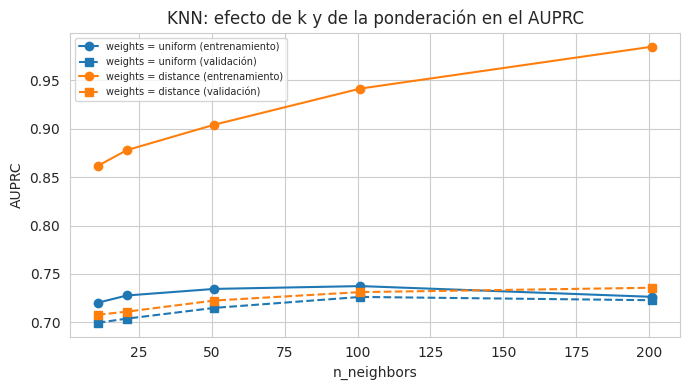

In [ ]:
grafica_efecto(
    tabla_knn, x="n_neighbors", grupo="weights",
    titulo="KNN: efecto de k y de la ponderación en el AUPRC",
    archivo="knn_efecto_hiperparametros"
)

## 12. Random Forest (ensamble de árboles)

Random Forest entrena muchos árboles de decisión sobre muestras distintas de los datos y combina sus votos. Los hiperparámetros que se prueban son:

- `n_estimators`: número de árboles.
- `max_depth`: profundidad máxima de cada árbol. Árboles muy profundos tienden a memorizar el entrenamiento.

Usa todos los datos con `class_weight="balanced_subsample"`, que pondera las clases dentro de cada árbol. Para que el tiempo sea manejable con 227 mil filas, cada árbol se entrena con una muestra aleatoria del 30 % de los datos (`max_samples=0.3`), distinta para cada árbol, de modo que el bosque completo sigue usando toda la información. Los valores de `max_samples` (0,3) y `min_samples_leaf` (5) se dejan fijos. Es el modelo que más tarda de los cinco.

In [ ]:
modelo_rf = Pipeline([
    ("prep", preprocesamiento),
    ("clf", RandomForestClassifier(
        class_weight="balanced_subsample",
        max_samples=0.3,
        min_samples_leaf=5,
        n_jobs=1,
        random_state=SEMILLA
    ))
])

malla_rf = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [8, 14],
}

busqueda_rf, tabla_rf = entrenar_modelo("Random Forest", modelo_rf, malla_rf)
tabla_rf

Random Forest: búsqueda terminada en 21.4 minutos
Mejores hiperparámetros: {'max_depth': 14, 'n_estimators': 200}
Mejor AUPRC en validación: 0.8035


,max_depth,n_estimators,AUPRC entrenamiento,AUPRC validación,Desv. AUPRC validación,Recall validación,Precision validación
0,8,100,0.9192,0.7964,0.0320,0.7858,0.8626
1,8,200,0.9209,0.7940,0.0312,0.7964,0.8560
2,14,100,0.9386,0.8023,0.0331,0.7672,0.8665
3,14,200,0.9382,0.8035,0.0314,0.7725,0.8641


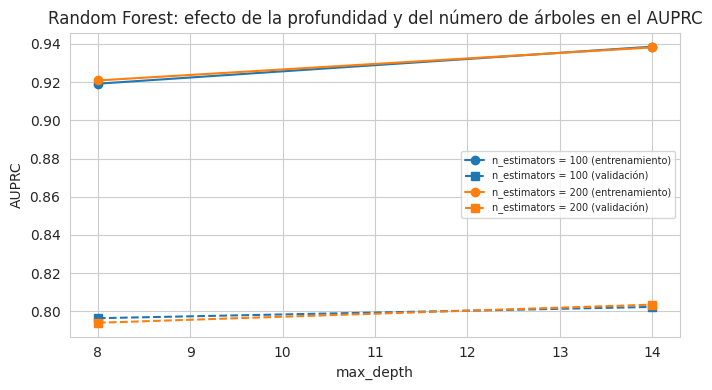

In [ ]:
grafica_efecto(
    tabla_rf, x="max_depth", grupo="n_estimators",
    titulo="Random Forest: efecto de la profundidad y del número de árboles en el AUPRC",
    archivo="random_forest_efecto_hiperparametros"
)

## 13. Red neuronal (MLP)

El perceptrón multicapa aprende combinaciones no lineales de las variables mediante capas de neuronas. Los hiperparámetros que se prueban son:

- `hidden_layer_sizes`: número de neuronas en cada capa oculta, por ejemplo `(32,)` es una capa de 32 neuronas y `(64, 32)` son dos capas.
- `alpha`: regularización. Un valor mayor limita el tamaño de los pesos y reduce el sobreajuste.

Usa submuestreo de la clase mayoritaria, porque `MLPClassifier` no permite ponderar las clases. El entrenamiento se detiene solo cuando deja de mejorar (`early_stopping`).

In [ ]:
modelo_mlp = Pipeline([
    ("prep", preprocesamiento),
    ("clf", ConSubmuestreo(estimador=MLPClassifier(
        activation="relu",
        max_iter=500,
        early_stopping=True,
        random_state=SEMILLA
    )))
])

malla_mlp = {
    "clf__estimador__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "clf__estimador__alpha": [0.0001, 0.01, 0.1],
}

busqueda_mlp, tabla_mlp = entrenar_modelo("Red neuronal", modelo_mlp, malla_mlp)
tabla_mlp

Red neuronal: búsqueda terminada en 1.9 minutos
Mejores hiperparámetros: {'alpha': 0.1, 'hidden_layer_sizes': (64, 32)}
Mejor AUPRC en validación: 0.7455


,alpha,hidden_layer_sizes,AUPRC entrenamiento,AUPRC validación,Desv. AUPRC validación,Recall validación,Precision validación
0,0.0001,"(32,)",0.7313,0.7164,0.0663,0.8043,0.6958
1,0.0001,"(64,)",0.7198,0.6982,0.0798,0.7832,0.7446
2,0.0001,"(64, 32)",0.7493,0.7413,0.0297,0.8175,0.7103
3,0.0001,"(128, 64)",0.7640,0.7342,0.0746,0.8229,0.6286
4,0.01,"(32,)",0.7343,0.7182,0.0680,0.8069,0.6933
5,0.01,"(64,)",0.7199,0.6983,0.0798,0.7832,0.7471
6,0.01,"(64, 32)",0.7593,0.7448,0.0338,0.8254,0.6628
7,0.01,"(128, 64)",0.7640,0.7342,0.0746,0.8229,0.6312
8,0.1,"(32,)",0.7215,0.7100,0.0607,0.8043,0.6181
9,0.1,"(64,)",0.7205,0.6986,0.0800,0.7832,0.7514


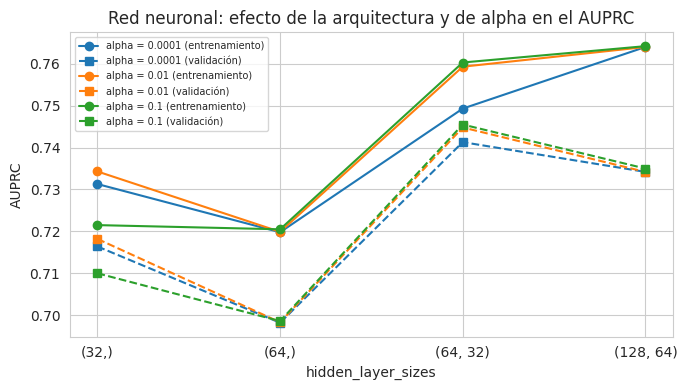

In [ ]:
grafica_efecto(
    tabla_mlp, x="hidden_layer_sizes", grupo="alpha",
    titulo="Red neuronal: efecto de la arquitectura y de alpha en el AUPRC",
    archivo="red_neuronal_efecto_hiperparametros"
)

## 14. Máquina de vectores de soporte (SVM)

La SVM busca la frontera que mejor separa las dos clases. Con un kernel lineal la frontera es un plano; con el kernel RBF puede ser curva. Los hiperparámetros que se prueban son:

- `kernel`: lineal o RBF.
- `C`: qué tanto se penalizan los errores en el entrenamiento. Un valor mayor ajusta más a los datos.

Con el kernel RBF se deja `gamma="scale"`. Usa submuestreo de la clase mayoritaria, porque el costo de la SVM crece muy rápido con el número de filas y con 227 mil sería demasiado lenta.

In [19]:
modelo_svm = Pipeline([
    ("prep", preprocesamiento),
    ("clf", ConSubmuestreo(estimador=SVC(gamma="scale")))
])


malla_svm = {
    "clf__estimador__kernel": ["linear", "rbf"],
    "clf__estimador__C": [0.01, 0.1, 1, 10],
}

busqueda_svm, tabla_svm = entrenar_modelo("SVM", modelo_svm, malla_svm)
tabla_svm

SVM: búsqueda terminada en 9.6 minutos
Mejores hiperparámetros: {'C': 0.01, 'kernel': 'linear'}
Mejor AUPRC en validación: 0.7477


,C,kernel,AUPRC entrenamiento,AUPRC validación,Desv. AUPRC validación,Recall validación,Precision validación
0,0.01,linear,0.7543,0.7477,0.0433,0.8016,0.7995
1,0.01,rbf,0.7313,0.7195,0.0764,0.0000,0.0000
2,0.1,linear,0.7566,0.7477,0.0386,0.8149,0.6987
3,0.1,rbf,0.7455,0.7258,0.0762,0.7752,0.7648
4,1.0,linear,0.7551,0.7471,0.0390,0.8175,0.6755
5,1.0,rbf,0.7711,0.7367,0.0690,0.8202,0.7331
6,10.0,linear,0.7538,0.7457,0.0394,0.8149,0.6734
7,10.0,rbf,0.7581,0.6749,0.1037,0.8466,0.5471


In [20]:
from sklearn.svm import LinearSVC

# Segunda versión de la SVM: sin submuestreo, usando ponderación de clases.
# Se usa LinearSVC (en vez de SVC con kernel="linear") porque escala mucho
# mejor con las ~227 mil filas de entrenamiento completas; el kernel RBF con
# todos los datos resultaba computacionalmente inviable para este proyecto.

modelo_svm_cw = Pipeline([
    ("prep", preprocesamiento),
    ("clf", LinearSVC(class_weight="balanced", max_iter=5000, random_state=SEMILLA))
])

malla_svm_cw = {
    "clf__C": [0.01, 0.1, 1, 10],
}

busqueda_svm_cw, tabla_svm_cw = entrenar_modelo("SVM (class_weight)", modelo_svm_cw, malla_svm_cw)
tabla_svm_cw

SVM (class_weight): búsqueda terminada en 0.9 minutos
Mejores hiperparámetros: {'C': 0.1}
Mejor AUPRC en validación: 0.7393


,C,AUPRC entrenamiento,AUPRC validación,Desv. AUPRC validación,Recall validación,Precision validación
0,0.01,0.7398,0.7392,0.0298,0.9047,0.0735
1,0.1,0.7402,0.7393,0.0295,0.9047,0.0734
2,1.0,0.7403,0.7392,0.0295,0.9047,0.0734
3,10.0,0.7403,0.7392,0.0295,0.9047,0.0734


In [21]:
mejor_submuestreo = tabla_svm.loc[tabla_svm["AUPRC validación"].idxmax()]
mejor_cw = tabla_svm_cw.loc[tabla_svm_cw["AUPRC validación"].idxmax()]

print("SVM con submuestreo   -> AUPRC validación:", round(mejor_submuestreo["AUPRC validación"], 4))
print("SVM con class_weight  -> AUPRC validación:", round(mejor_cw["AUPRC validación"], 4))

SVM con submuestreo   -> AUPRC validación: 0.7477
SVM con class_weight  -> AUPRC validación: 0.7393


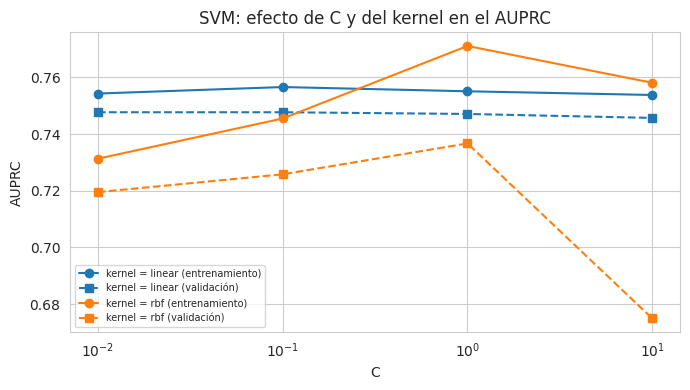

In [ ]:
grafica_efecto(
    tabla_svm, x="C", grupo="kernel",
    titulo="SVM: efecto de C y del kernel en el AUPRC",
    archivo="svm_efecto_hiperparametros",
    x_log=True
)

## 15. Comparación de los cinco modelos

Se resume el mejor resultado de cada modelo en validación, con el intervalo de confianza del 95 % calculado a partir de las 5 particiones. También se muestra el tiempo promedio que tardó en ajustarse cada modelo con sus mejores hiperparámetros.

In [ ]:
filas = []
for nombre, busqueda in resultados_modelos.items():
    r = busqueda.cv_results_
    i = busqueda.best_index_

    m_tr, _ = resumen_con_ic(r, i, "average_precision", "train")
    m_va, h_va = resumen_con_ic(r, i, "average_precision", "test")

    fila = {
        "Modelo": nombre,
        "Mejores hiperparámetros": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in busqueda.best_params_.items()),
        "AUPRC entrenamiento": round(m_tr, 4),
        "AUPRC validación": round(m_va, 4),
        "IC 95 % (±)": round(h_va, 4),
    }
    for clave, etiqueta in [("roc_auc", "ROC-AUC"), ("precision", "Precision"),
                            ("recall", "Recall"), ("f1", "F1-score"), ("mcc", "MCC")]:
        fila[f"{etiqueta} validación"] = round(r[f"mean_test_{clave}"][i], 4)
    fila["Tiempo de ajuste (s)"] = round(r["mean_fit_time"][i], 1)
    filas.append(fila)

comparacion = pd.DataFrame(filas).sort_values("AUPRC validación", ascending=False).reset_index(drop=True)
comparacion.to_csv(f"{CARPETA_RESULTADOS}/comparacion_modelos.csv", index=False)
comparacion

,Modelo,Mejores hiperparámetros,AUPRC entrenamiento,AUPRC validación,IC 95 % (±),ROC-AUC validación,Precision validación,Recall validación,F1-score validación,MCC validación,Tiempo de ajuste (s)
0,Random Forest,"max_depth=14, n_estimators=200",0.9382,0.8035,0.0436,0.9697,0.8641,0.7725,0.8139,0.8158,131.8
1,Regresión logística,C=0.1,0.7568,0.7545,0.0355,0.9814,0.0605,0.9153,0.1133,0.2315,2.1
2,SVM,"C=0.01, kernel=linear",0.7543,0.7477,0.0601,0.9801,0.7995,0.8016,0.7984,0.7991,0.4
3,Red neuronal,"alpha=0.1, hidden_layer_sizes=(64, 32)",0.7603,0.7455,0.0450,0.9774,0.6787,0.8254,0.7403,0.7457,1.3
4,KNN,"n_neighbors=201, weights=distance",0.9849,0.7358,0.0332,0.9774,0.8580,0.7275,0.7849,0.7885,0.1


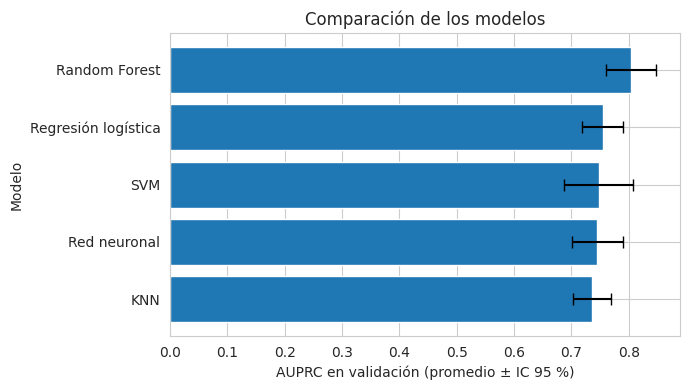

In [ ]:
orden = comparacion.sort_values("AUPRC validación")

plt.figure(figsize=(7, 4))
plt.barh(orden["Modelo"], orden["AUPRC validación"], xerr=orden["IC 95 % (±)"], capsize=4)

plt.xlabel("AUPRC en validación (promedio ± IC 95 %)")
plt.ylabel("Modelo")
plt.title("Comparación de los modelos")
plt.tight_layout()

plt.savefig(f"{CARPETA_RESULTADOS}/comparacion_modelos.png", dpi=200)
plt.show()

## 16. Hiperparámetros analizados

Resumen de las mallas de valores probadas para cada modelo. Esta tabla es la base de la tabla de hiperparámetros del reporte.

In [ ]:
filas = []
for nombre, malla in mallas_usadas.items():
    for parametro, valores in malla.items():
        filas.append({
            "Modelo": nombre,
            "Hiperparámetro": parametro.split("__")[-1],
            "Valores evaluados": ", ".join(str(v) for v in valores),
        })

tabla_hiperparametros = pd.DataFrame(filas)
tabla_hiperparametros.to_csv(f"{CARPETA_RESULTADOS}/hiperparametros_evaluados.csv", index=False)
tabla_hiperparametros

,Modelo,Hiperparámetro,Valores evaluados
0,Regresión logística,C,"0.001, 0.01, 0.1, 1, 10, 100"
1,KNN,n_neighbors,"11, 21, 51, 101, 201"
2,KNN,weights,"uniform, distance"
3,Random Forest,n_estimators,"100, 200"
4,Random Forest,max_depth,"8, 14"
5,Red neuronal,hidden_layer_sizes,"(32,), (64,), (64, 32), (128, 64)"
6,Red neuronal,alpha,"0.0001, 0.01, 0.1"
7,SVM,kernel,"linear, rbf"
8,SVM,C,"0.01, 0.1, 1, 10"


## 17. Interpretación y siguientes pasos

- Modelo con mejor AUPRC en validación: Random Forest (0,8035 ± 0,0436). La regresión logística, la SVM, la red neuronal y KNN quedan entre 0,736 y 0,755, y todos los intervalos de confianza se solapan, por lo que la diferencia entre ellos no es concluyente.
- Sobreajuste: solo Random Forest muestra una brecha importante entre entrenamiento (0,9382) y validación (0,8035). En la regresión logística, la SVM y la red neuronal la diferencia es menor a 0,015. El AUPRC de entrenamiento de KNN no es comparable.
- Hiperparámetros: la regresión logística y `alpha` en la red neuronal casi no influyen. En la SVM, el kernel lineal iguala o supera al RBF con todos los valores de C. En la red neuronal, la arquitectura (64, 32) fue la mejor. En KNN, Random Forest y otros el mejor valor quedó en el borde de la malla, por lo que no se descartan mejores valores fuera de ella.
- Precision, recall y F1 dependen del umbral 0,5. El AUPRC no, y por eso es la métrica principal. La regresión logística tiene F1 y MCC bajos (0,11 y 0,23) por una precision de 0,06, pero ordena las transacciones tan bien como los demás modelos.
- Costo de ajuste: KNN tardó 25,2 minutos en la búsqueda, la SVM 9,0 y la red neuronal 1,4. Random Forest tarda 124,7 segundos por ajuste, frente a menos de 2 segundos en los demás modelos.

##18. Evaluación en el conjunto de prueba

Hasta aquí todas las decisiones (hiperparámetros, comparación de modelos) se tomaron con la validación cruzada sobre el conjunto de entrenamiento. Ahora cada modelo, con los mejores hiperparámetros que eligió su búsqueda, se evalúa una sola vez en el conjunto de prueba, que hasta este momento no se había usado. Después de ver estos resultados no se vuelven a cambiar hiperparámetros; si se hiciera, el conjunto de prueba dejaría de ser independiente.

El modelo final de cada búsqueda (best_estimator_) ya fue reajustado con todo el conjunto de entrenamiento.

Los intervalos de confianza del 95 % se calculan con bootstrap: se remuestrean con reemplazo las transacciones de prueba 1000 veces, se calculan las métricas en cada remuestreo y se toman los percentiles 2,5 y 97,5. Como el conjunto de prueba tiene solo unos 95 fraudes, se esperan intervalos amplios.

In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score

B = 1000   # número de remuestreos bootstrap
rng = np.random.default_rng(SEMILLA)

y_test_np = y_test.to_numpy()
n_test = len(y_test_np)

cv_umbral = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


def puntuaciones(modelo, X):
    """Puntuación continua de "fraude", necesaria para AUPRC y ROC-AUC."""
    if hasattr(modelo, "decision_function"):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]


def puntuaciones_oof(modelo, X, y, cv):
    """Igual que puntuaciones(), pero con predicciones fuera de pliegue sobre entrenamiento."""
    if hasattr(modelo, "decision_function"):
        return cross_val_predict(modelo, X, y, cv=cv, method="decision_function", n_jobs=-1)
    return cross_val_predict(modelo, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]


def mejor_umbral(y, puntaje):
    """Umbral que maximiza F1, barriendo 200 valores entre el min y el max del puntaje."""
    candidatos = np.linspace(puntaje.min(), puntaje.max(), 200)
    valores_f1 = [f1_score(y, (puntaje >= u).astype(int)) for u in candidatos]
    return candidatos[int(np.argmax(valores_f1))]


def metricas_etiquetas(y, pred):
    """Precision, recall, F1 y MCC a partir de las predicciones (umbral elegido fuera de pliegue)."""
    tp = np.sum((y == 1) & (pred == 1))
    fp = np.sum((y == 0) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))
    tn = np.sum((y == 0) & (pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    denominador = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = (tp * tn - fp * fn) / denominador if denominador > 0 else 0.0
    return [precision, recall, f1, mcc]


nombres_metricas = ["AUPRC", "ROC-AUC", "Precision", "Recall", "F1-score", "MCC"]
resultados_test = {}
resultados_modelos["SVM (class_weight)"] = busqueda_svm_cw

for nombre, busqueda in resultados_modelos.items():
    modelo = busqueda.best_estimator_
    puntaje = puntuaciones(modelo, X_test)

    # --- umbral elegido fuera de pliegue, solo con datos de entrenamiento ---
    puntaje_oof = puntuaciones_oof(modelo, X_train, y_train, cv_umbral)
    umbral = mejor_umbral(y_train.to_numpy(), puntaje_oof)
    pred = (puntaje >= umbral).astype(int)

    estimado = [average_precision_score(y_test_np, puntaje), roc_auc_score(y_test_np, puntaje)]
    estimado += metricas_etiquetas(y_test_np, pred)

    remuestreos = np.empty((B, len(nombres_metricas)))
    for b in range(B):
        idx = rng.integers(0, n_test, n_test)
        yb, sb, pb = y_test_np[idx], puntaje[idx], pred[idx]
        remuestreos[b] = [average_precision_score(yb, sb), roc_auc_score(yb, sb)] + metricas_etiquetas(yb, pb)

    inferior, superior = np.percentile(remuestreos, [2.5, 97.5], axis=0)
    resultados_test[nombre] = {"estimado": estimado, "inferior": inferior, "superior": superior, "umbral": umbral}
    print(f"{nombre}: AUPRC en prueba = {estimado[0]:.4f}  IC 95 % [{inferior[0]:.4f}, {superior[0]:.4f}]  (umbral elegido={umbral:.3f})")

Regresión logística: AUPRC en prueba = 0.6852  IC 95 % [0.5825, 0.7855]  (umbral elegido=14.186)
KNN: AUPRC en prueba = 0.6766  IC 95 % [0.5678, 0.7820]  (umbral elegido=0.352)
Random Forest: AUPRC en prueba = 0.7833  IC 95 % [0.7007, 0.8691]  (umbral elegido=0.432)
Red neuronal: AUPRC en prueba = 0.7092  IC 95 % [0.5972, 0.8055]  (umbral elegido=0.889)
SVM: AUPRC en prueba = 0.7072  IC 95 % [0.6030, 0.8022]  (umbral elegido=0.991)


In [ ]:
filas = []
for nombre, res_t in resultados_test.items():
    fila = {"Modelo": nombre}
    for j, metrica in enumerate(nombres_metricas):
        fila[f"{metrica} prueba"] = f"{res_t['estimado'][j]:.4f} [{res_t['inferior'][j]:.4f}, {res_t['superior'][j]:.4f}]"
    filas.append(fila)

tabla_prueba = pd.DataFrame(filas)
tabla_prueba.to_csv(f"{CARPETA_RESULTADOS}/resultados_prueba.csv", index=False)
tabla_prueba

,Modelo,AUPRC prueba,ROC-AUC prueba,Precision prueba,Recall prueba,F1-score prueba,MCC prueba
0,Regresión logística,"0.6852 [0.5825, 0.7855]","0.9657 [0.9388, 0.9869]","0.8765 [0.8023, 0.9403]","0.7474 [0.6600, 0.8283]","0.8068 [0.7407, 0.8634]","0.8091 [0.7461, 0.8648]"
1,KNN,"0.6766 [0.5678, 0.7820]","0.9643 [0.9375, 0.9849]","0.8750 [0.7901, 0.9429]","0.7368 [0.6451, 0.8208]","0.8000 [0.7300, 0.8586]","0.8027 [0.7354, 0.8604]"
2,Random Forest,"0.7833 [0.7007, 0.8691]","0.9553 [0.9233, 0.9829]","0.8659 [0.7887, 0.9375]","0.7474 [0.6628, 0.8364]","0.8023 [0.7376, 0.8646]","0.8041 [0.7401, 0.8650]"
3,Red neuronal,"0.7092 [0.5972, 0.8055]","0.9595 [0.9252, 0.9864]","0.8537 [0.7716, 0.9231]","0.7368 [0.6442, 0.8211]","0.7910 [0.7165, 0.8519]","0.7928 [0.7192, 0.8533]"
4,SVM,"0.7072 [0.6030, 0.8022]","0.9635 [0.9337, 0.9873]","0.8875 [0.8082, 0.9506]","0.7474 [0.6585, 0.8302]","0.8114 [0.7441, 0.8691]","0.8141 [0.7480, 0.8699]"


### Entrenamiento, validación y prueba

La guía pide mostrar los resultados de los tres conjuntos. Esta tabla junta, para cada modelo, el AUPRC en entrenamiento y validación (promedio de la validación cruzada) y en prueba (con su intervalo de confianza). Para KNN, el valor de entrenamiento no es comparable (ver sección 11).

In [ ]:
filas = []
for _, fila_cmp in comparacion.iterrows():
    nombre = fila_cmp["Modelo"]
    res_t = resultados_test[nombre]
    filas.append({
        "Modelo": nombre,
        "AUPRC entrenamiento": fila_cmp["AUPRC entrenamiento"],
        "AUPRC validación (± IC 95 %)": f"{fila_cmp['AUPRC validación']:.4f} ± {fila_cmp['IC 95 % (±)']:.4f}",
        "AUPRC prueba [IC 95 %]": f"{res_t['estimado'][0]:.4f} [{res_t['inferior'][0]:.4f}, {res_t['superior'][0]:.4f}]",
    })

tabla_tres_conjuntos = pd.DataFrame(filas)
tabla_tres_conjuntos.to_csv(f"{CARPETA_RESULTADOS}/auprc_entrenamiento_validacion_prueba.csv", index=False)
tabla_tres_conjuntos

,Modelo,AUPRC entrenamiento,AUPRC validación (± IC 95 %),AUPRC prueba [IC 95 %]
0,Random Forest,0.9382,0.8035 ± 0.0436,"0.7833 [0.7007, 0.8691]"
1,Regresión logística,0.7568,0.7545 ± 0.0355,"0.6852 [0.5825, 0.7855]"
2,SVM,0.7543,0.7477 ± 0.0601,"0.7072 [0.6030, 0.8022]"
3,Red neuronal,0.7603,0.7455 ± 0.0450,"0.7092 [0.5972, 0.8055]"
4,KNN,0.9849,0.7358 ± 0.0332,"0.6766 [0.5678, 0.7820]"


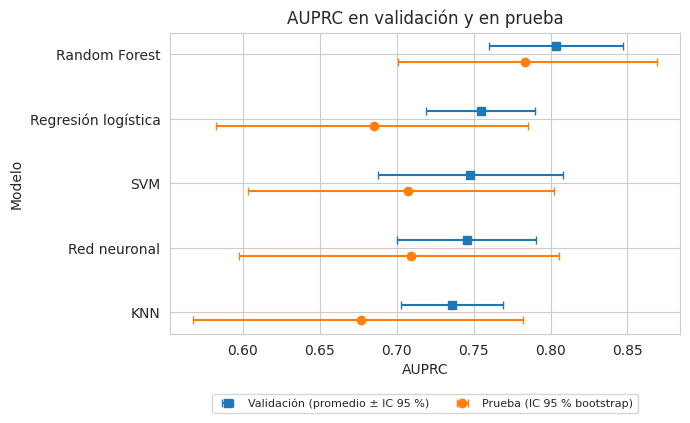

In [ ]:
orden = comparacion.sort_values("AUPRC validación").reset_index(drop=True)
posiciones = np.arange(len(orden))

est_prueba = np.array([resultados_test[m]["estimado"][0] for m in orden["Modelo"]])
inf_prueba = np.array([resultados_test[m]["inferior"][0] for m in orden["Modelo"]])
sup_prueba = np.array([resultados_test[m]["superior"][0] for m in orden["Modelo"]])

plt.figure(figsize=(7, 4.4))
plt.errorbar(orden["AUPRC validación"], posiciones + 0.12, xerr=orden["IC 95 % (±)"],
             fmt="s", capsize=3, label="Validación (promedio ± IC 95 %)")
plt.errorbar(est_prueba, posiciones - 0.12, xerr=[est_prueba - inf_prueba, sup_prueba - est_prueba],
             fmt="o", capsize=3, label="Prueba (IC 95 % bootstrap)")

plt.yticks(posiciones, orden["Modelo"])
plt.xlabel("AUPRC")
plt.ylabel("Modelo")
plt.title("AUPRC en validación y en prueba")
plt.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()

plt.savefig(f"{CARPETA_RESULTADOS}/auprc_validacion_vs_prueba.png", dpi=200, bbox_inches="tight")
plt.show()